# LogSieve experiments, Week 14

This notebook is the experimental plan for LogSieve and the first measurements I trust enough to put in the proposal. LogSieve is a Ferragina-Manzini index (FM-index) over a security log. The index is the Burrows-Wheeler Transform (BWT) stored in a wavelet tree, plus a sampled suffix array. I compare count queries with a plain suffix array, Knuth-Morris-Pratt (KMP), a `str.find` loop, and a naive scan. The seed is 5300. Each timed call is repeated so I can report the mean, the sample standard deviation, the median, and the interquartile range (IQR). The collector is disabled during a timed call.

The sizes in this run are prefixes of the OpenSSH log at 2,000, 10,000, and 50,000 lines, when `data/raw/SSH.log` is available. Larger prefixes, from about 1 MB up to about 20 MB, are sketched at the end and are not run yet. If the full log is missing, the harness uses the committed 2,000 line sample and the bigger prefixes collapse to that file.


In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "sample" / "OpenSSH_2k.log").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from logsieve.bench import SEED, run_week14

print("repo", ROOT)
print("seed", SEED)
summary = run_week14(seed=SEED, repeats=5, quick=False, output_dir=ROOT / "results")
print("timing file", summary["timing_csv"])
print("charts", len(summary["charts"]))


repo /workspace
seed 5300


timing file /workspace/results/early_benchmarks.csv
charts 7


## Setup and the machine

The cell above writes `results/environment.json` before it starts timing. I want the Python version, the operating system, the CPU, the RAM, the git commit, and the seed in one place so a later run on my own PC can be compared with this one instead of being mixed into it. The next cell prints that file. The fit of build time on log log axes is stored there too, and it is computed from the medians of this run.


In [2]:
env = json.loads((ROOT / "results" / "environment.json").read_text())
shown = {key: env[key] for key in (
    "python_version", "implementation", "os", "cpu", "cpu_count", "ram_bytes",
    "git_commit", "git_dirty", "seed", "repeats", "warmup",
    "gc_disabled_during_timed_sections", "openssh_source", "line_counts",
    "locate_pattern", "loglog_fit",
) if key in env}
print(json.dumps(shown, indent=2))


{
  "python_version": "3.12.3",
  "implementation": "CPython",
  "os": "Linux-6.12.113+-x86_64-with-glibc2.39",
  "cpu": "Intel(R) Xeon(R) Processor",
  "cpu_count": 4,
  "ram_bytes": 16780623872,
  "git_commit": "ec2004087526eb2ac9304ad10a45a65703b96240",
  "git_dirty": false,
  "seed": 5300,
  "repeats": 5,
  "warmup": 1,
  "gc_disabled_during_timed_sections": true,
  "openssh_source": "/workspace/data/raw/SSH.log",
  "line_counts": [
    2000,
    10000,
    50000
  ],
  "locate_pattern": "error",
  "loglog_fit": {
    "fm_total_loglog_slope": 1.1213086499933818,
    "fm_total_loglog_intercept": -15.606076215701833,
    "points": [
      {
        "text_bytes": 223218,
        "median_seconds": 0.16958082900009686
      },
      {
        "text_bytes": 1098049,
        "median_seconds": 0.9485745150000184
      },
      {
        "text_bytes": 5561038,
        "median_seconds": 6.237819065999929
      }
    ]
  }
}


## Datasets and the query workload

The logs are the Loghub collection (Zhu et al. 2023), Zenodo record 8196385. The committed samples are `OpenSSH_2k.log` and `Linux_2k.log`. The full OpenSSH log is the unpacked `SSH.tar.gz` archive. A synthetic control uses the same number of body bytes as each OpenSSH prefix, drawn from a small printable alphabet with the same seed recipe, so I can see whether repetition in the real log changes the wavelet size.

The workload mixes three kinds of pattern. Random slices of length 4, 8, 16, 32, and 64 are taken from the log body with `random.Random(seed + line_count)`. Fixed analyst strings are "Failed password", "Invalid user", "authentication failure", "error", and "Accepted", plus the first IPv4 address in the prefix and its three octet prefix when one exists. One absent string, "zzqxvnotpresent", is included so a miss is timed too. Aho-Corasick is timed on watch lists of 10, 50, and 100 strings drawn from the 2,000 line prefix. A list of 500 strings is a Week 15 run.


## Correctness

I do not time a method until it agrees with the naive scan. For every pattern in the workload the harness compares FM-index count, KMP count, the `str.find` count, and suffix array binary search with the naive count. When a pattern has at most 30 hits, it also compares the located positions. The run raises if any of those checks fail. The next cell repeats a small version of that check in the notebook so the agreement is visible without opening the harness.


In [3]:
from logsieve.baselines import find_count, kmp_count, naive_count, naive_search
from logsieve.fm_index import FMIndex
from logsieve.ingest import load_log
from logsieve.suffix_array import build_suffix_array, suffix_array_count, suffix_array_search

log = load_log(ROOT / "data" / "sample" / "OpenSSH_2k.log", max_lines=80)
text = log.text
index = FMIndex(text, sample_rate=8)
sa = build_suffix_array(text)
patterns = [b"Invalid user", b"error", b"zzqxvnotpresent", text[20:28], b""]
rows = []
for pattern in patterns:
    naive_hits = naive_search(text, pattern)
    row = {
        "pattern": pattern.decode("utf-8", "backslashreplace")[:40],
        "naive": len(naive_hits),
        "kmp": kmp_count(text, pattern),
        "str_find": find_count(text, pattern),
        "sa": suffix_array_count(text, sa, pattern),
        "fm": index.count(pattern),
        "locate_matches": index.locate(pattern) == naive_hits,
    }
    rows.append(row)
pd.DataFrame(rows)


,pattern,naive,kmp,str_find,sa,fm,locate_matches
0,Invalid user,5,5,5,5,5,True
1,error,0,0,0,0,0,True
2,zzqxvnotpresent,0,0,0,0,0,True
3,Z sshd[2,80,80,80,80,80,True
4,,8715,8715,8715,8715,8715,True


## E1, build cost

For each prefix I build the FM-index five times and record the inner clocks for the suffix array, the BWT, the wavelet tree, the samples, and the total. The plot uses the median of those five trials on log log axes. A fitted slope is a description of these three sizes, not a proof of the asymptotic bound. Week 15 adds more sizes and a faster suffix array construction.


In [4]:
summary_df = pd.read_csv(ROOT / "results" / "early_benchmarks_summary.csv")
build = summary_df[summary_df.experiment == "e1_build"].sort_values(["method", "lines"])
cols = ["method", "lines", "text_bytes", "trials", "mean_seconds", "std_seconds", "median_seconds", "iqr_seconds"]
build[cols]


,method,lines,text_bytes,trials,mean_seconds,std_seconds,median_seconds,iqr_seconds
1,bwt,2000,223218,5,0.000493,0.000135,0.000437,0.000003
71,bwt,10000,1098049,5,0.003002,0.000150,0.002985,0.000077
141,bwt,50000,5561038,5,0.030356,0.000965,0.029890,0.000915
4,fm_total,2000,223218,5,0.169977,0.001177,0.169581,0.000644
74,fm_total,10000,1098049,5,0.961847,0.032500,0.948575,0.046109
144,fm_total,50000,5561038,5,6.249755,0.081193,6.237819,0.029871
3,samples,2000,223218,5,0.014929,0.000310,0.014876,0.000407
73,samples,10000,1098049,5,0.077681,0.003635,0.076671,0.006500
143,samples,50000,5561038,5,0.468456,0.005258,0.470500,0.006190
0,suffix_array,2000,223218,5,0.144710,0.000387,0.144659,0.000201


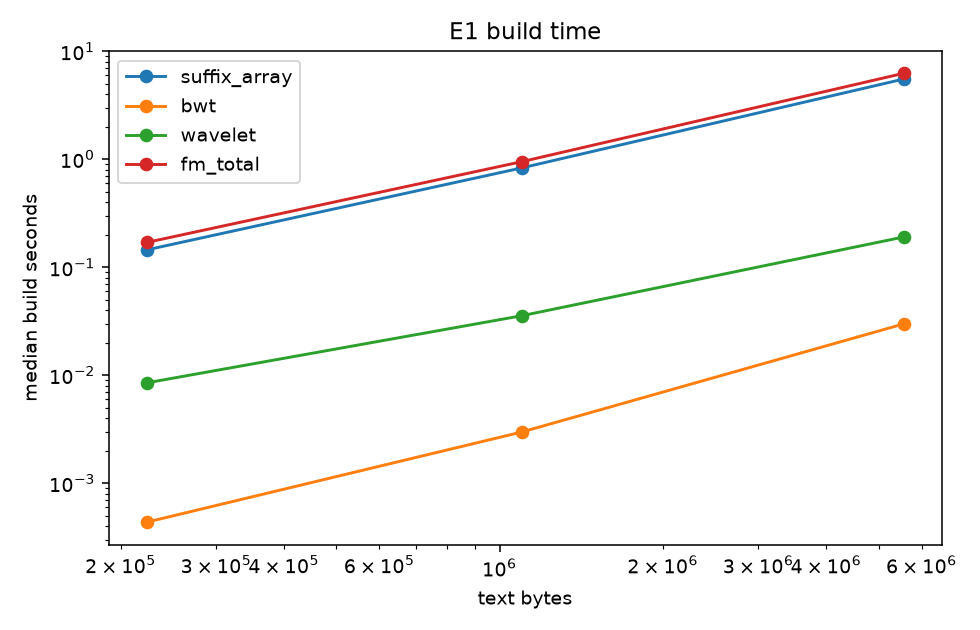

log log slope for fm_total 1.1213086499933818


In [5]:
display(Image(filename=str(ROOT / "results" / "e1_build_time.png")))
print("log log slope for fm_total", env["loglog_fit"].get("fm_total_loglog_slope"))


## E2, space

Space is measured once per text, because the structures are deterministic. I record the raw text, a numpy int32 suffix array, the same array stored as a Python list of integers (object headers included), the packed wavelet bits, the rank directory, the suffix array samples, and the retained BWT array. `fm_index_bytes` adds those index pieces and does not include the original text. `bits_per_char` is the number of wavelet bit vector entries divided by the text length, which is the bit cost of the tree before packing and before the rank directory. The synthetic rows are the random controls at the same body length. The Linux row is the committed 2,000 line Linux sample.


In [6]:
space = pd.read_csv(ROOT / "results" / "space_measurements.csv")
keep = ["dataset", "lines", "text_bytes", "sa_numpy_bytes", "sa_python_bytes",
        "wavelet_packed_bytes", "rank_directory_bytes", "wavelet_bits", "bits_per_char",
        "sample_bytes", "bwt_bytes", "fm_index_bytes", "fm_without_raw_bwt_bytes", "distinct_symbols"]
space[keep]


,dataset,lines,text_bytes,sa_numpy_bytes,sa_python_bytes,wavelet_packed_bytes,rank_directory_bytes,wavelet_bits,bits_per_char,sample_bytes,bwt_bytes,fm_index_bytes,fm_without_raw_bwt_bytes,distinct_symbols
0,openssh,2000,223218,892872,8035904,184904,23880,1477312,6.618248,223248,223218,657298,434080,70
1,synthetic,1,223218,892872,8035904,168320,21488,1345037,6.025665,223248,223218,638322,415104,41
2,openssh,10000,1098049,4392196,39529820,908184,114288,7262942,6.614406,1098064,1098049,3220633,2122584,70
3,synthetic,1,1098049,4392196,39529820,827080,103840,6615244,6.024544,1098064,1098049,3129081,2031032,41
4,openssh,50000,5561038,22244152,200197424,4597296,575536,36775914,6.613138,5561056,5561038,16296974,10735936,73
5,synthetic,1,5561038,22244152,200197424,4188184,524000,33504133,6.024798,5561056,5561038,15836326,10275288,41
6,linux,2000,214487,857948,7721588,179536,23384,1433698,6.684312,214512,214487,633967,419480,81


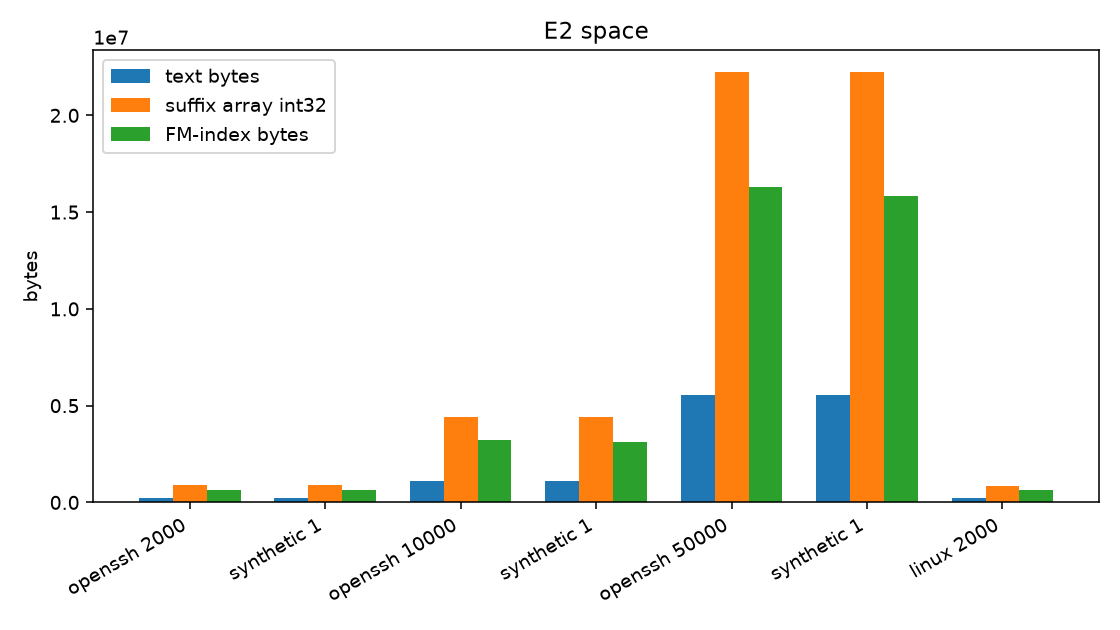

In [7]:
display(Image(filename=str(ROOT / "results" / "e2_space.png")))


## E3, count query latency

Count queries are timed after the index and the suffix array already exist, so the build is not mixed into the query. The naive scan, KMP, and `str.find` only count. They do not build a hit list. The size plot is the random length 8 pattern. The length plot is the random patterns on the largest prefix. Analyst strings and the absent string are in the CSV with `pattern_kind` set, and they are not on those two lines. Median and IQR are in the summary table. Mean and standard deviation are the variance I want next to the median, because a single average would hide a slow trial.


In [8]:
counts = summary_df[summary_df.experiment == "e3_count"]
view = counts[counts.pattern_kind.isin(["random", "analyst", "absent", "ip"])]
view.groupby(["lines", "method", "pattern_kind", "pattern_len"], as_index=False)[
    ["mean_seconds", "std_seconds", "median_seconds", "iqr_seconds", "matches"]
].median(numeric_only=True)


,lines,method,pattern_kind,pattern_len,mean_seconds,std_seconds,median_seconds,iqr_seconds,matches
0,2000,fm_count,absent,15,0.000045,0.000001,0.000044,1.521000e-06,0.0
1,2000,fm_count,analyst,5,0.000059,0.000003,0.000059,2.210000e-06,47.0
2,2000,fm_count,analyst,8,0.000100,0.000003,0.000100,1.209000e-06,1.0
3,2000,fm_count,analyst,12,0.000141,0.000006,0.000139,2.011000e-06,113.0
4,2000,fm_count,analyst,15,0.000173,0.000007,0.000170,9.680000e-07,520.0
...,...,...,...,...,...,...,...,...,...
190,50000,str_find,random,4,0.002813,0.000056,0.002792,2.471000e-05,15290.0
191,50000,str_find,random,8,0.003833,0.000065,0.003810,6.989200e-05,10618.0
192,50000,str_find,random,16,0.003500,0.000056,0.003499,1.018730e-04,15290.0
193,50000,str_find,random,32,0.000982,0.000061,0.000953,1.582600e-05,1.0


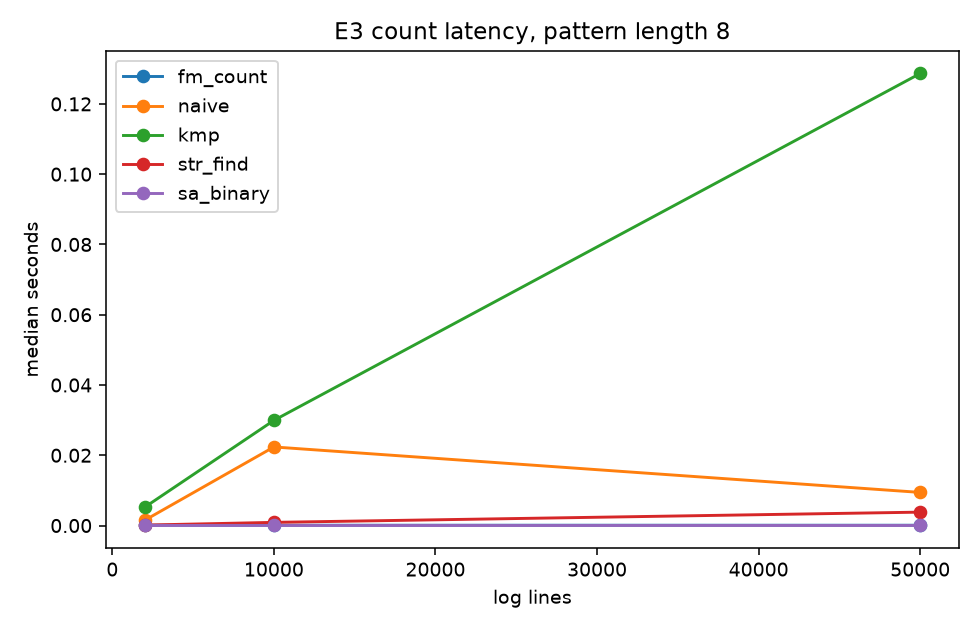

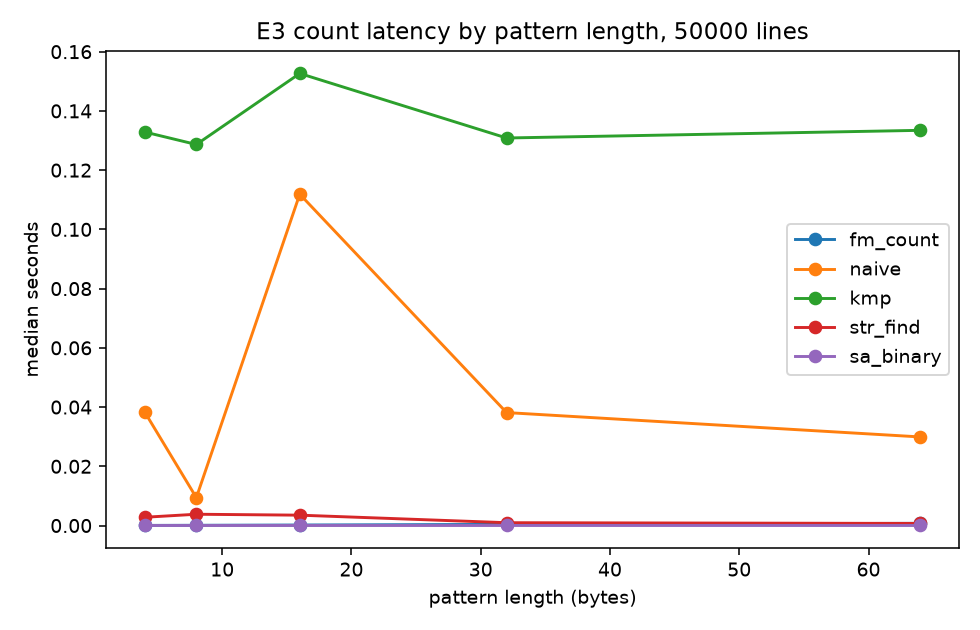

In [9]:
display(Image(filename=str(ROOT / "results" / "e3_latency_vs_size.png")))
display(Image(filename=str(ROOT / "results" / "e3_latency_vs_length.png")))


## E4, sample rate, small scale

Locate walks the LF mapping until it hits a sampled text position. The sample rate k is the gap between stored positions, so a larger k stores less and walks farther. This Week 14 curve is on the 2,000 line prefix only. Rebuilding a 50,000 line index once per sample rate is Week 15 work, after the suffix array build is cheaper. The pattern is chosen in the harness as the busiest workload string that still has at most 80 hits, and its text is stored in `environment.json` under `locate_pattern`. The right axis of the chart is the measured sample bytes, not a formula.


In [10]:
locate = summary_df[summary_df.experiment == "e4_locate"].sort_values("sample_rate")
locate[["sample_rate", "pattern", "matches", "mean_seconds", "std_seconds", "median_seconds", "iqr_seconds"]]


,sample_rate,pattern,matches,mean_seconds,std_seconds,median_seconds,iqr_seconds
210,4,error,47,0.001605,0.000073,0.001617,0.000080
211,8,error,47,0.002465,0.000057,0.002437,0.000028
212,16,error,47,0.004141,0.000098,0.004111,0.000138
213,32,error,47,0.007455,0.000057,0.007420,0.000095
214,64,error,47,0.013133,0.000139,0.013063,0.000139


In [11]:
memory = pd.read_csv(ROOT / "results" / "sample_rate_memory.csv")
memory


,lines,text_bytes,sample_rate,matches,pattern,sample_bytes,sample_count,fm_index_bytes,fm_without_raw_bwt_bytes
0,2000,223218,4,47,error,892896,55806,1326946,1103728
1,2000,223218,8,47,error,446464,27904,880514,657296
2,2000,223218,16,47,error,223248,13953,657298,434080
3,2000,223218,32,47,error,111632,6977,545682,322464
4,2000,223218,64,47,error,55824,3489,489874,266656


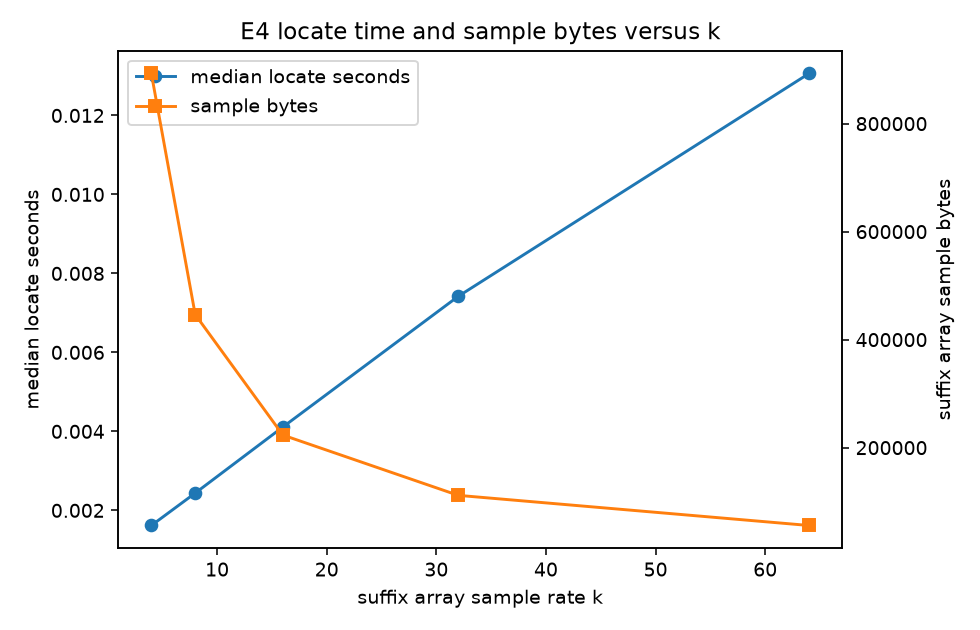

In [12]:
display(Image(filename=str(ROOT / "results" / "e4_sample_tradeoff.png")))


## E5, many patterns, small scale

One Aho-Corasick pass over the 2,000 line prefix is compared with repeating KMP and with repeating FM-index counts, for 10, 50, and 100 patterns. The patterns are random length 8 slices. A watch list of 500, and the same comparison on a much longer log, is the Week 15 version of this experiment. The question I want answered there is where the index pays for its build when the analyst already has a batch of patterns and a single online pass can find all of them.


In [13]:
watch = summary_df[summary_df.experiment == "e5_watch"].sort_values(["matches", "method"])
watch[["method", "matches", "lines", "mean_seconds", "std_seconds", "median_seconds", "iqr_seconds"]]


,method,matches,lines,mean_seconds,std_seconds,median_seconds,iqr_seconds
215,aho_corasick,10,2000,0.018441,0.000413,0.018308,0.000333
217,fm_repeated,10,2000,0.000893,0.000053,0.000865,0.000032
216,kmp_repeated,10,2000,0.053394,0.000191,0.053446,0.000240
218,aho_corasick,50,2000,0.021677,0.000502,0.021654,0.000252
220,fm_repeated,50,2000,0.004391,0.000070,0.004379,0.000041
219,kmp_repeated,50,2000,0.269594,0.003598,0.268350,0.004191
221,aho_corasick,100,2000,0.024768,0.000479,0.024953,0.000143
223,fm_repeated,100,2000,0.008897,0.000375,0.008752,0.000062
222,kmp_repeated,100,2000,0.536532,0.001593,0.536737,0.001487


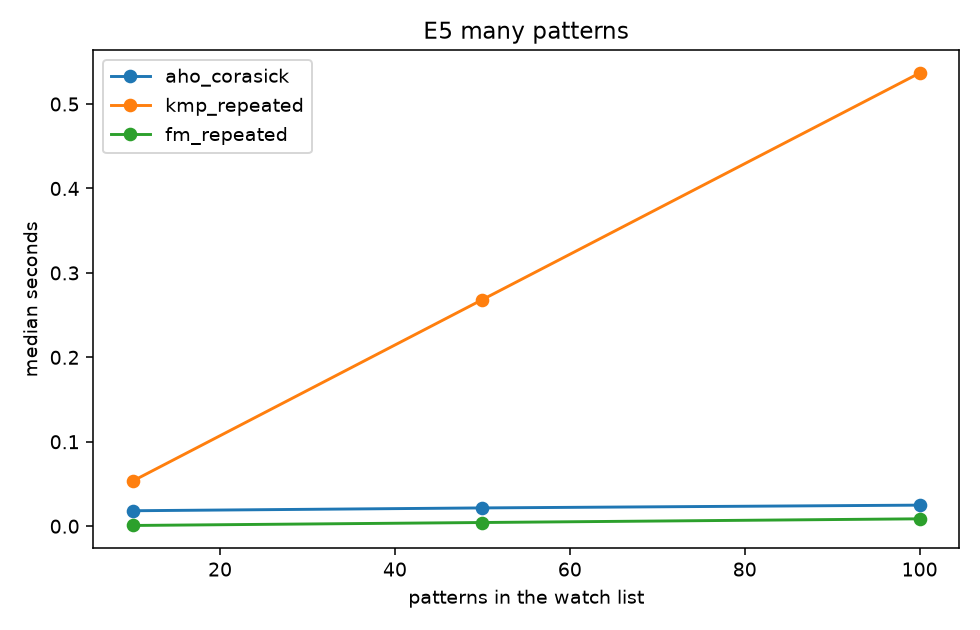

In [14]:
display(Image(filename=str(ROOT / "results" / "e5_many_patterns.png")))


## E6, Count-Min sketch, stretch

The Count-Min sketch estimates how often each IPv4 address appears. It never returns a count below the true count. I compare it with `collections.Counter` on the largest prefix in this run. Width changes and depth stays at 4. The exact counter's Python object size is measured with `sys.getsizeof` on the counter and on each key. This is a small sweep. A wider error curve, and a top talker list that does not start from the exact key set, belongs to Week 15.


In [15]:
sketch = pd.read_csv(ROOT / "results" / "sketch_measurements.csv")
sketch


,lines,distinct_ips,total_updates,width,depth,seed,max_overestimate,mean_overestimate,sketch_bytes,exact_counter_bytes
0,50000,124,47320,16,4,5300,33205,1903.620968,512,13912
1,50000,124,47320,64,4,5300,4827,151.016129,2048,13912
2,50000,124,47320,256,4,5300,379,17.137097,8192,13912
3,50000,124,47320,1024,4,5300,379,7.612903,32768,13912


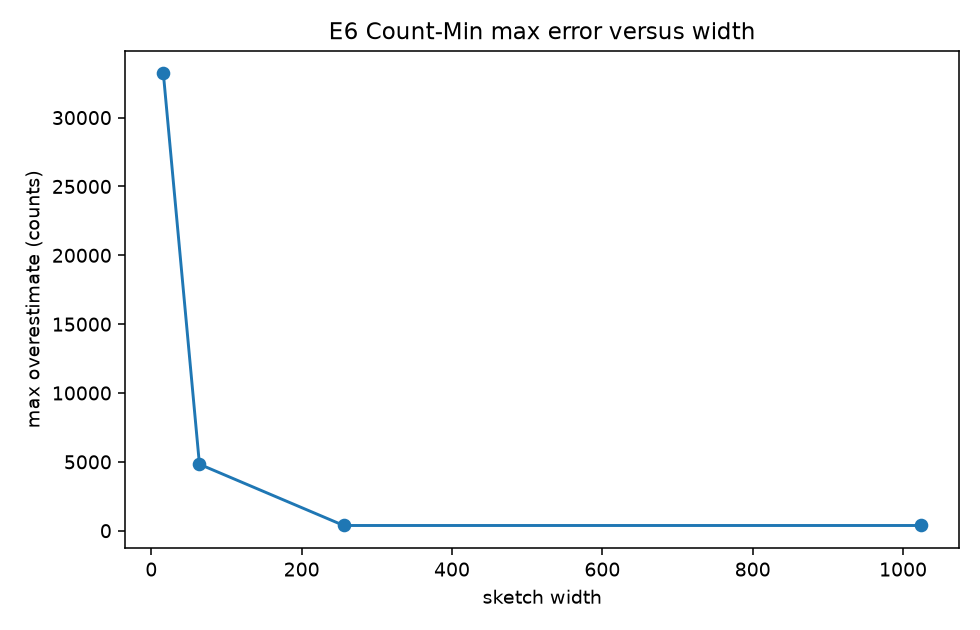

In [16]:
display(Image(filename=str(ROOT / "results" / "e6_sketch_error.png")))


## Break even

Amakobe section 14.3 is the reason this table exists. The build must be paid for by later queries. I take the median FM-index build time and compare the median `str.find` count with the median FM-index count across the workload at that size. If the index is faster per query, the number of queries that pay for the build is the build time divided by that gap. If the index is slower per query, the status column says so and the crossover cell is left blank. The medians that go into the division are the medians of the per pattern medians, so one very common string does not decide the whole size by itself.


In [17]:
pd.read_csv(ROOT / "results" / "breakeven.csv")


,lines,text_bytes,build_median_seconds,str_find_median_seconds,fm_count_median_seconds,queries_to_break_even,status
0,2000,223218,0.169581,0.000087,0.000139,NaN,index_not_faster_per_query
1,10000,1098049,0.948575,0.000502,0.000140,2619.995235,index_faster_per_query
2,50000,5561038,6.237819,0.002353,0.000147,2828.425946,index_faster_per_query


## Threats to validity, and what Week 15 still must run

These numbers are from one machine, the one named in `environment.json`. A second machine, including the Windows PC I will use for the final numbers, can move the constant factors around even when the ordering of the methods stays put. The collector is off during timed calls, and there is one warmup, but the file cache and the CPU frequency are not pinned. Python object overhead is part of the space result. The rank directory and the Python suffix array list are much larger than the textbook bit counts, and I report both the wavelet bit entries and the bytes actually allocated.

The naive scan in this harness skips ahead with `bytes.find` on the first byte of the pattern and then checks the rest. That is still a linear scan, and its worst case is still proportional to the product of the lengths. It is a C assisted scan, while KMP here is a pure Python loop, so a slow KMP time is partly the interpreter. The report will call that gap an implementation effect.

Week 15 still must run the prefixes at 1, 2, 5, 10, and 20 MB, a suffix array construction that is closer to linear time, locate on the larger prefixes, a watch list of 500 patterns, and a Count-Min sweep that chooses its own candidates. The cell below only records that plan. It does not build those indexes.


In [18]:
def week15_plan():
    """Skeleton for the runs that are too heavy for this pass."""
    return {
        "prefixes_mb": [1, 2, 5, 10, 20],
        "suffix_array": "radix doubling or SA-IS, still checked against this builder",
        "locate_lines": [10000, 50000],
        "watch_sizes": [10, 50, 100, 500],
        "sketch": "sweep width and depth, and keep a candidate heap",
    }

print("planned for Week 15")
for key, value in week15_plan().items():
    print(key, value)


planned for Week 15
prefixes_mb [1, 2, 5, 10, 20]
suffix_array radix doubling or SA-IS, still checked against this builder
locate_lines [10000, 50000]
watch_sizes [10, 50, 100, 500]
sketch sweep width and depth, and keep a candidate heap
